In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 39.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
# Data processing
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Splitting dataset
from sklearn.model_selection import train_test_split

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Pipeline
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Save trained models
import joblib
import os
import json

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Display first five records
print("First five records:")
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Dataset Shape: (45211, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Check target distribution
print("\nTarget Distribution:")
print(df["y"].value_counts())

# Target distribution percentage
print("\nTarget Percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Duplicate Records: 0

Target Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


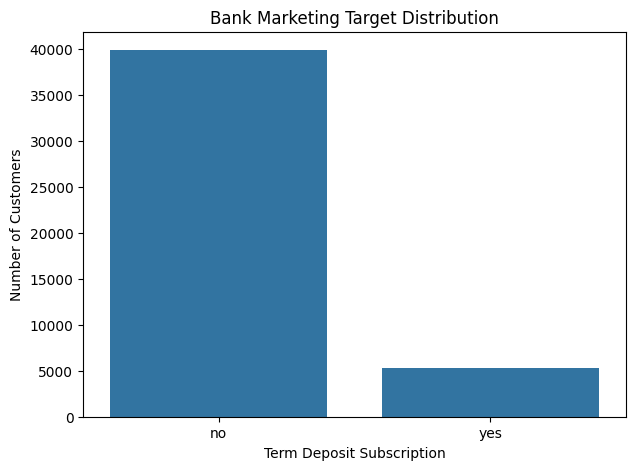

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Bank Marketing Target Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()

In [6]:
# Independent variables
X = df.drop(
    columns=["y", "duration"]
)

# Dependent variable
y = df["y"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Columns:")
print(X.columns.tolist())

Input Features Shape: (45211, 15)
Target Shape: (45211,)

Input Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [7]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (36168, 15)
Testing Data: (9043, 15)

Training Target Distribution:
y
no     0.883018
yes    0.116982
Name: proportion, dtype: float64

Testing Target Distribution:
y
no     0.883003
yes    0.116997
Name: proportion, dtype: float64


In [10]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=5
        ),

    "Naive Bayes":
        GaussianNB(),

    "Support Vector Machine":
        LinearSVC(
            random_state=42,
            max_iter=5000
        )

}

print("Five classification models created!")

Five classification models created!


In [11]:
trained_models = {}

for name, classifier in models.items():

    print("Training:", name)

    # Create preprocessing + model pipeline
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Store trained model
    trained_models[name] = pipeline

    print(name, "completed successfully!\n")


print("All five models trained successfully!")

Training: Logistic Regression
Logistic Regression completed successfully!

Training: Decision Tree
Decision Tree completed successfully!

Training: KNN
KNN completed successfully!

Training: Naive Bayes
Naive Bayes completed successfully!

Training: Support Vector Machine
Support Vector Machine completed successfully!

All five models trained successfully!


In [12]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print("\nModel:", name)
    print("First 10 Predictions:", y_pred[:10])


Model: Logistic Regression
First 10 Predictions: ['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

Model: Decision Tree
First 10 Predictions: ['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'yes' 'no']

Model: KNN
First 10 Predictions: ['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

Model: Naive Bayes
First 10 Predictions: ['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

Model: Support Vector Machine
First 10 Predictions: ['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [13]:
results = []

# Convert actual target values to binary
y_test_binary = (y_test == "yes").astype(int)

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Get probability or decision scores for AUC
    if hasattr(model, "predict_proba"):

        y_scores = model.predict_proba(X_test)[:, 1]

    else:

        y_scores = model.decision_function(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test_binary,
        y_scores
    )

    precision = precision_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        pos_label="yes",
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    # Store results
    results.append({

        "ML Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc

    })


# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display results
display(results_df.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8933,0.7717,0.6632,0.1786,0.2815,0.3065
1,Decision Tree,0.8309,0.6132,0.2982,0.3289,0.3128,0.2170
2,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,Support Vector Machine,0.8932,0.7682,0.6513,0.1871,0.2907,0.3101


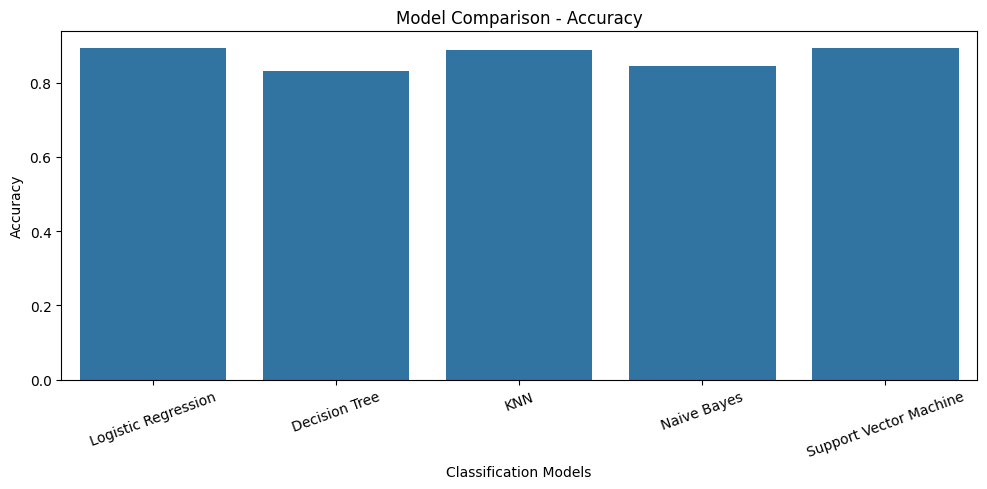

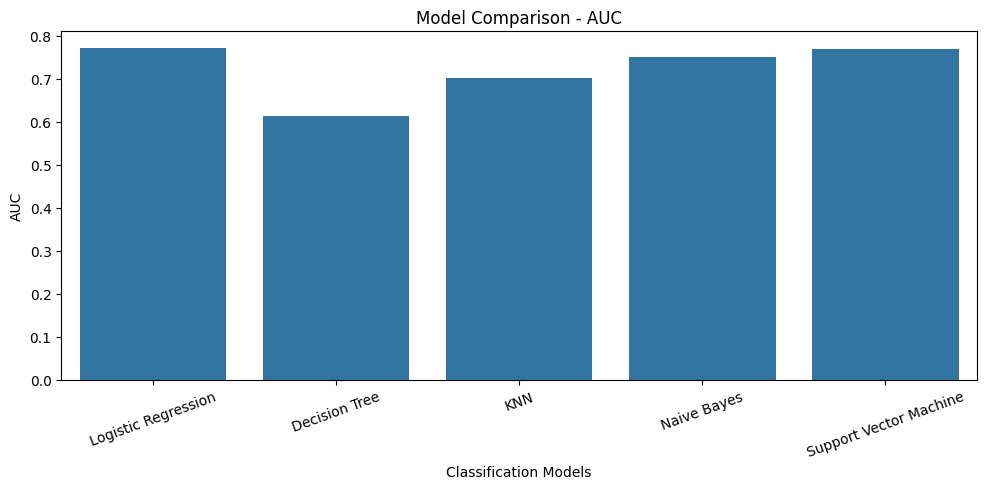

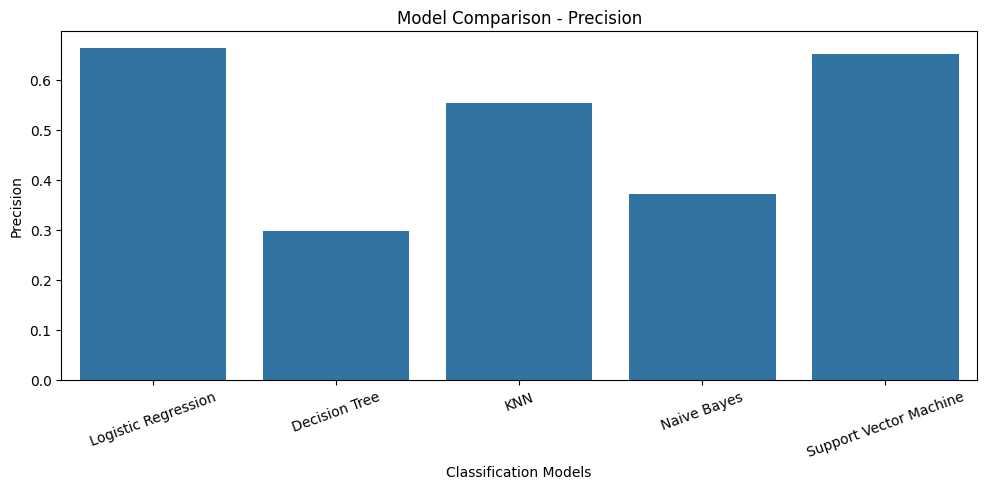

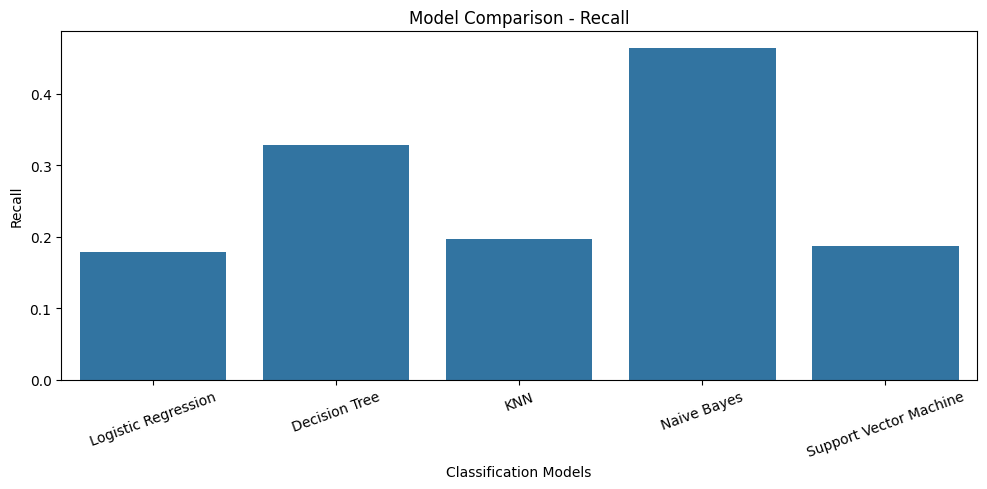

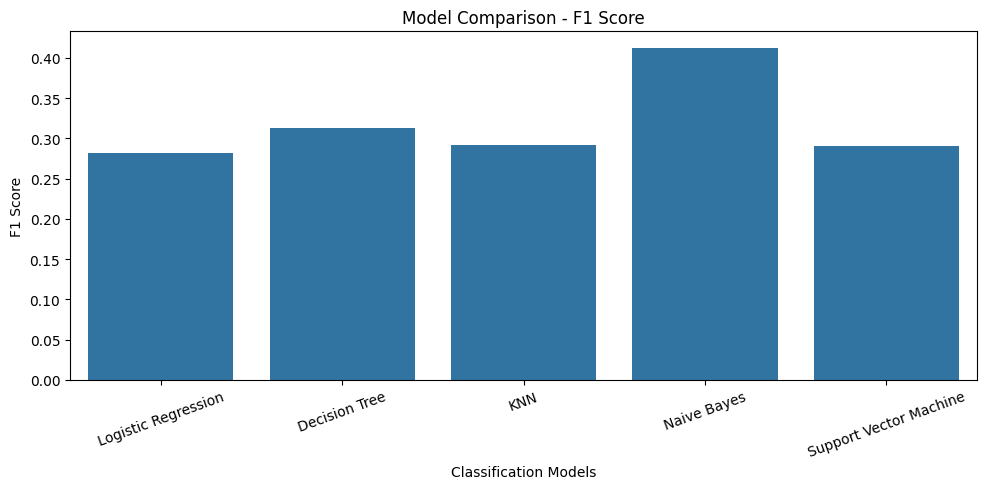

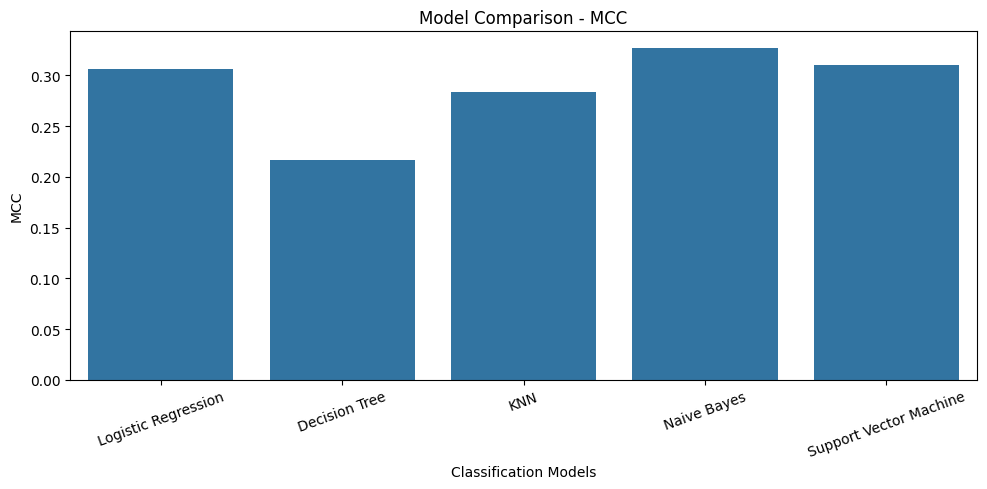

In [14]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="ML Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Models")
    plt.ylabel(metric)

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

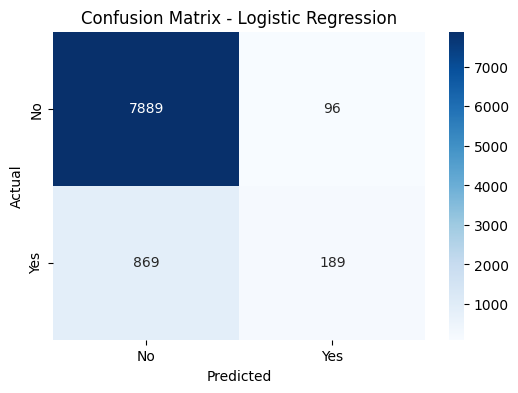

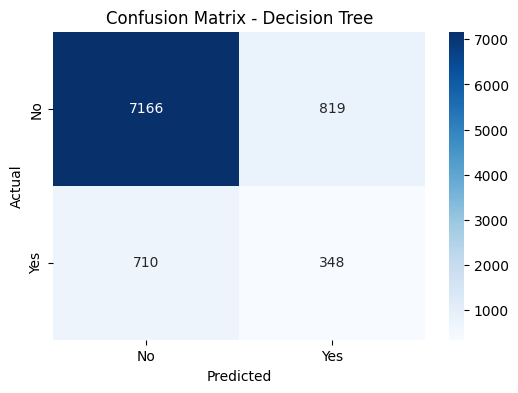

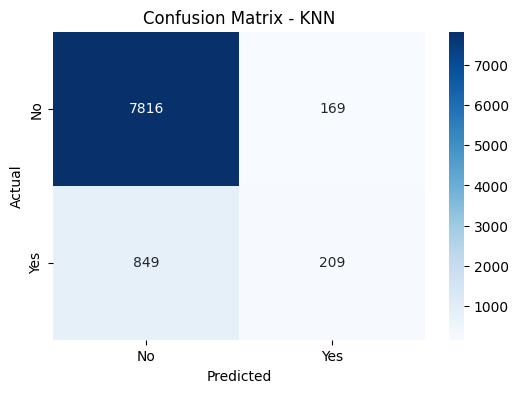

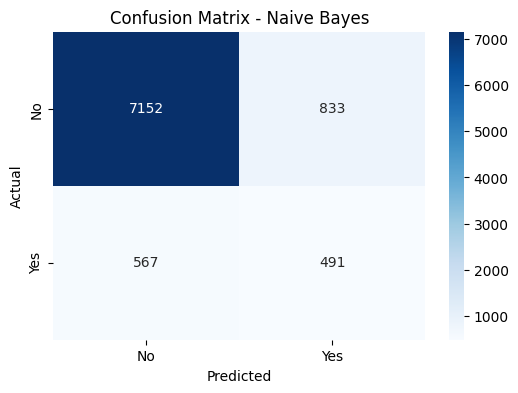

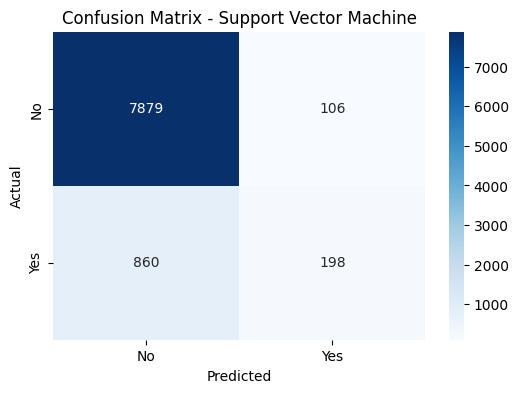

In [15]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [16]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n===================================")
    print("MODEL:", name)
    print("===================================")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["no", "yes"],
            target_names=["No Subscription", "Subscription"],
            zero_division=0
        )
    )


MODEL: Logistic Regression
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043


MODEL: Decision Tree
                 precision    recall  f1-score   support

No Subscription       0.91      0.90      0.90      7985
   Subscription       0.30      0.33      0.31      1058

       accuracy                           0.83      9043
      macro avg       0.60      0.61      0.61      9043
   weighted avg       0.84      0.83      0.83      9043


MODEL: KNN
                 precision    recall  f1-score   support

No Subscription       0.90      0.98      0.94      7985
   Subscription       0.55      0.20      0.29      1058

       accuracy                           0.89      9043
      macro avg   

In [17]:
# Create model directory
os.makedirs("model", exist_ok=True)

# Save models
for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + ".joblib"
    )

    filepath = os.path.join(
        "model",
        filename
    )

    joblib.dump(model, filepath)

    print("Saved:", filepath)

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/support_vector_machine.joblib


In [18]:
# Combine testing features and actual target
test_data = X_test.copy()

test_data["y"] = y_test.values

# Save CSV
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

Test dataset saved successfully!
Test dataset shape: (9043, 16)


In [19]:
results_df.to_csv(
    "model_results.csv",
    index=False
)

print("Model evaluation results saved!")

Model evaluation results saved!


In [20]:
with open("feature_columns.json", "w") as f:

    json.dump(
        X.columns.tolist(),
        f
    )

print("Feature information saved!")

Feature information saved!


In [22]:
import os

print("Project files:")

for root, dirs, files in os.walk("."):
    for file in files:
        if not file.startswith("."):
            print(os.path.join(root, file))

Project files:
./bank-full.csv
./feature_columns.json
./test_data.csv
./model_results.csv
./.config/active_config
./.config/default_configs.db
./.config/config_sentinel
./.config/gce
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/configurations/config_default
./.config/logs/2026.10.26/22.18.53.588181.log
./.config/logs/2026.10.26/22.18.15.518759.log
./.config/logs/2026.10.26/22.18.38.571729.log
./.config/logs/2026.10.26/22.18.52.867204.log
./.config/logs/2026.10.26/22.18.45.880512.log
./.config/logs/2026.10.26/22.18.44.768076.log
./model/knn.joblib
./model/decision_tree.joblib
./model/naive_bayes.joblib
./model/support_vector_machine.joblib
./model/logistic_regression.joblib
./sample_data/anscombe.json
./sample_data/README.md
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_test.csv
./sample_data/mnist_train_small.csv


In [23]:
import os
import shutil

project_files = [
    "model",
    "test_data.csv",
    "model_results.csv",
    "feature_columns.json"
]

os.makedirs("ML_Assignment_2", exist_ok=True)

for item in project_files:
    if os.path.isdir(item):
        shutil.copytree(
            item,
            f"ML_Assignment_2/{item}",
            dirs_exist_ok=True
        )
    else:
        shutil.copy2(
            item,
            f"ML_Assignment_2/{item}"
        )

shutil.make_archive(
    "ML_Assignment_2",
    "zip",
    "ML_Assignment_2"
)

from google.colab import files
files.download("ML_Assignment_2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import pandas as pd
import json

print("MODEL RESULTS")
display(pd.read_csv("model_results.csv"))

print("\nFEATURE COLUMNS")
with open("feature_columns.json") as f:
    features = json.load(f)

print(features)
print("Total features:", len(features))

print("\nTEST DATA")
test_df = pd.read_csv("test_data.csv")
display(test_df.head())

print("Test data shape:", test_df.shape)
print("Target distribution:")
print(test_df["y"].value_counts())

MODEL RESULTS


,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.893288,0.771749,0.663158,0.178639,0.281459,0.306530
1,Decision Tree,0.830919,0.613178,0.298201,0.328922,0.312809,0.217011
2,KNN,0.887427,0.702749,0.552910,0.197543,0.291086,0.283266
3,Naive Bayes,0.845184,0.751441,0.370846,0.464083,0.412259,0.327093
4,Support Vector Machine,0.893177,0.768214,0.651316,0.187146,0.290749,0.310055



FEATURE COLUMNS
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Total features: 15

TEST DATA


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown,no
1,44,technician,married,secondary,no,378,yes,no,unknown,30,may,2,-1,0,unknown,no
2,31,services,married,secondary,no,356,yes,no,unknown,20,jun,5,-1,0,unknown,no
3,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,4,-1,0,unknown,no
4,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,unknown,no


Test data shape: (9043, 16)
Target distribution:
y
no     7985
yes    1058
Name: count, dtype: int64
